# Imports

In [ ]:
import os
import pandas as pd
import numpy as np
from scipy.stats import norm, gaussian_kde
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch


# Setup

In [141]:
##############################
# Read Dataset into Dataframe
##############################

# path to cleaned dataset
clean_path = r'../data/mnz_cleaned.csv'


##### read into df...
df = pd.read_csv(clean_path)

##### drop analyses >5% analytical error...
df['percent'] = df['error'] / df['age'] * 100
mask = df['percent'] < 5
df = df.loc[mask]
df.sort_values('error', inplace=True)
df.reset_index(inplace=True)
df.head()

,index,sample,zone,mnz,texture,texture_chem,n,age,error,CaO,...,Dy2O3,Ho2O3,Er2O3,Tm2O3,Yb2O3,SO3,PbO,lree,HREE,percent
0,8,EB14-001,CMZI,m28,overgrowth,Y depleted overgrowth,6.0,348.85,0.701308,0.995224,...,0.181849,0.021200,0.034744,0.069987,0.009827,0.019002,0.097798,60.335048,1.371961,0.201034
1,111,P14-003-2B,MDHSZ,m50,core,Th enriched core,5.0,307.14,0.794103,1.435283,...,0.010042,0.010042,0.010042,0.020180,0.010042,0.018376,0.134090,58.128568,0.677921,0.258548
2,176,P14-005A-5B,CBSZ,m20,core,Y depleted core,NaN,356.00,0.800000,0.827626,...,0.125878,0.009912,0.014868,0.009912,0.009912,0.020815,0.080285,62.602214,1.604702,0.224719
3,114,M1605-2-L3,MDHSZ,m4,rim,Y depleted rim,5.0,298.70,1.381304,0.852869,...,0.062720,0.009927,0.009927,0.009927,0.009927,0.016638,0.084487,62.652220,1.401806,0.462438
4,31,WA14-002,CMZI,m22,rim,Y depleted rim,5.0,353.24,1.461027,0.984389,...,0.079168,0.009819,0.009819,0.061324,0.009819,0.015049,0.087027,61.816443,1.415405,0.413607


# K-Means

## Determine Number of Clusters

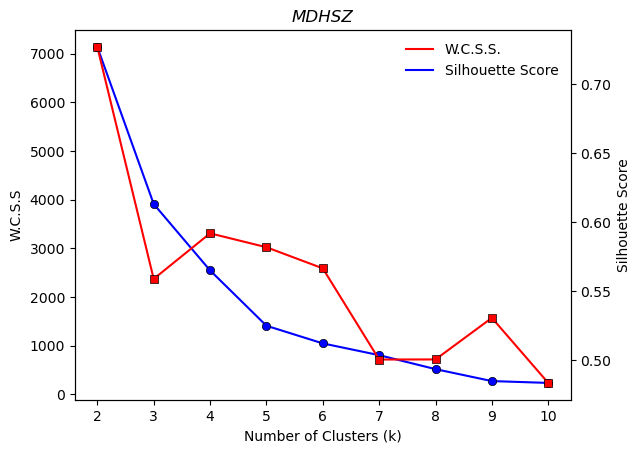

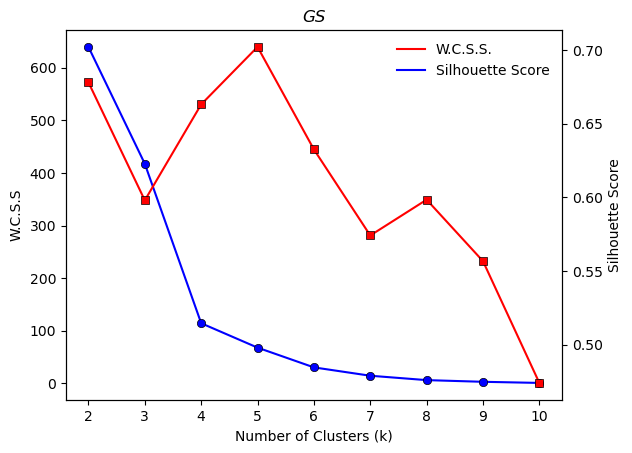

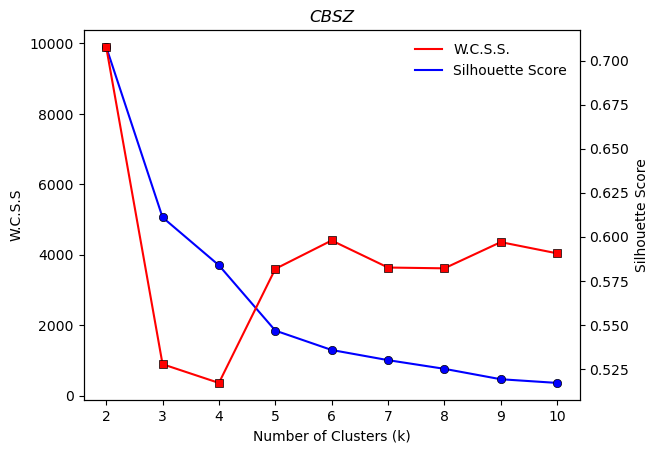

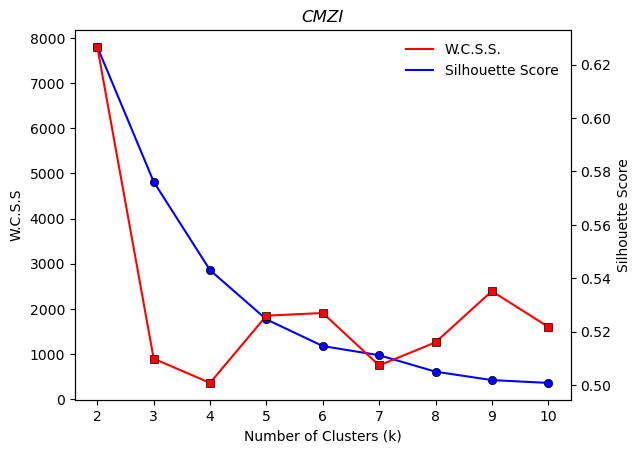

In [142]:


for zone in ['MDHSZ', 'GS', 'CBSZ', 'CMZI']:

    df_subset = df[df['zone']==zone]

    ages = df_subset['age'].to_numpy().reshape(-1,1)
    errors = df_subset['error'].to_numpy().reshape(-1,1)
    clusters = np.arange(2, 11, 1)
    inertias = []
    sil_scores = []
    for k in clusters:
        kmeans = KMeans(n_clusters=k, random_state=111, n_init='auto').fit(ages)
        inertias.append(kmeans.inertia_)
        sil_scores.append(silhouette_score(ages, kmeans.labels_))
    
    fig, ax = plt.subplots()
    ax.plot(clusters, inertias, color='blue', marker='o', markeredgecolor='k', markeredgewidth=0.5)
    ax2 = ax.twinx()
    ax2.plot(clusters, sil_scores, color='red', marker='s', markeredgecolor='k', markeredgewidth=0.5)

    legend_items = [Line2D([0], [0], color='red', label='W.C.S.S.'), 
                    Line2D([0], [0], color='blue', label='Silhouette Score')]
    
    ax.legend(legend_items, [l.get_label() for l in legend_items], loc='upper right', bbox_to_anchor=(1,1), frameon=False)

    ax.set_title(zone, style='italic')
    ax.set_xlabel('Number of Clusters (k)')
    ax.set_ylabel('W.C.S.S')
    ax2.set_ylabel('Silhouette Score')
    


## Final Cluster Labels

In [136]:
from scipy.stats import t

def cluster_stats(ages, se, two_sigma=False):
    # ages = np.asarray(ages, float)
    # se   = np.asarray(se, float)
    n    = len(ages)
    w    = 1.0 / (se**2)

    # Weighted mean
    mu = np.sum(w * ages) / np.sum(w)

    # MSWD (χ²/(n-1))
    chi2 = np.sum(w * (ages - mu)**2)
    mswd = chi2 / max(n - 1, 1)

    # Uncertainty on the mean (inflate if MSWD>1)
    sigma_mu = np.sqrt(1.0 / np.sum(w))
    sigma_mu_adj = sigma_mu * np.sqrt(mswd) if mswd > 1 else sigma_mu

    # 95% CI (or 2σ if you prefer)
    if two_sigma:
        half_width = 2.0 * sigma_mu_adj
    else:
        tcrit = t.ppf(0.975, df=max(n - 1, 1))
        half_width = tcrit * sigma_mu_adj

    return {
        "mean": mu,
        "mswd": mswd,
        "n": n,
        "sigma_mean": sigma_mu_adj,
        "ci95_halfwidth": half_width
    }



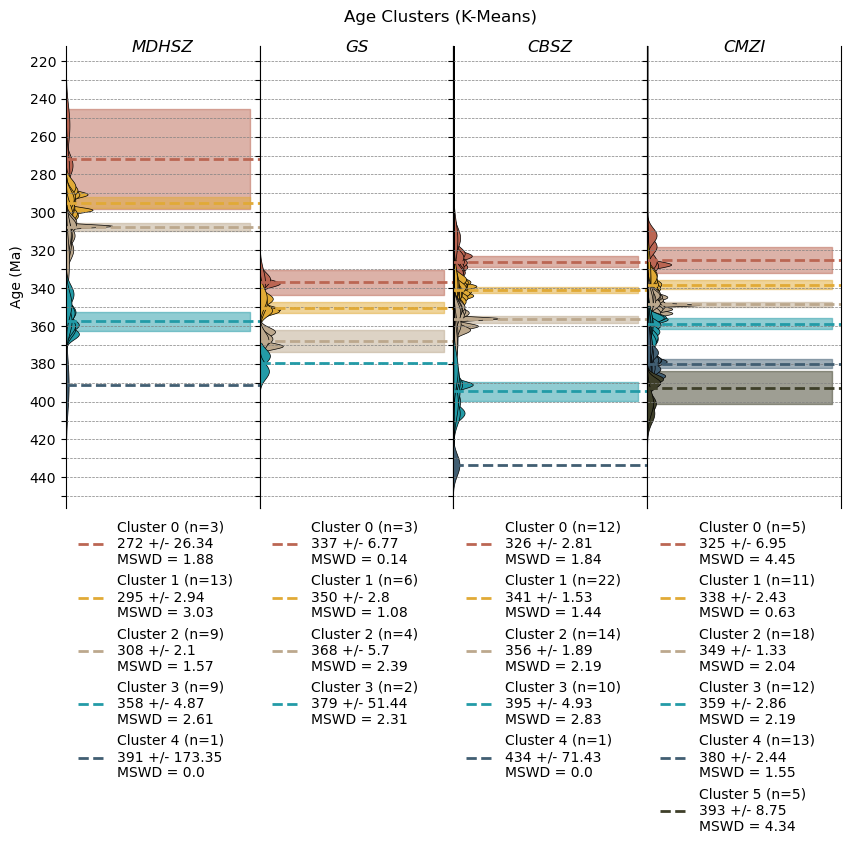

In [168]:
fig, ax = plt.subplots(nrows=1, ncols=4, sharey=True, figsize=(10,6))
plt.subplots_adjust(wspace=0)


zone_clusters = {'MDHSZ': 5, 
                 'GS': 4, 
                 'CBSZ': 5, 
                 'CMZI': 6}

k_colors = ['#BB6653', '#E1AA36', '#BCA88D', '#239BA7', '#415E72', '#3E3F29']


all_stats = {}


for idx, zone in enumerate(zone_clusters.keys()):

    all_stats[zone] = {}

    df_subset = df[df['zone']==zone].copy()
    all_ages = df_subset['age'].to_numpy().reshape(-1,1)
    all_errors = df_subset['error'].to_numpy().reshape(-1,1)

    kmeans = KMeans(n_clusters=zone_clusters[zone], random_state=111, n_init='auto').fit(all_ages) 
    # df_subset['labels'] = kmeans.labels_.ravel()

    # Sort the centers
    order = np.argsort(kmeans.cluster_centers_.ravel())

    # Relabel the cluster assignments
    labels = kmeans.labels_
    relabel = np.empty_like(order)
    relabel[order] = np.arange(order.size)
    df_subset['labels'] = relabel[labels]

    # Reorder the centers too (optional)
    kmeans.cluster_centers_ = kmeans.cluster_centers_[order]

    df_subset.sort_values(['labels', 'error'], inplace=True)
    df_subset.reset_index(drop=True, inplace=True)


    for k in df_subset['labels'].unique():

        ages = df_subset.loc[df_subset['labels'] == k, 'age'].to_numpy()
        errors = df_subset.loc[df_subset['labels'] == k, 'error'].to_numpy()
        stats = cluster_stats(ages, errors, two_sigma=False)
        all_stats[zone][k] = stats
        

        for _, row in df_subset[df_subset['labels'] == k].iterrows():
            mean = row['age']
            error = row['error']
            k_label = row['labels']
            age_range = np.linspace(mean - 4 * error, mean + 4 * error, 100)
            density = norm.pdf(age_range, mean, error)
            ax[idx].fill_between(density, age_range, alpha=1, color=k_colors[k_label], linewidth=0.5, edgecolor='k')
        
        label = f"Cluster {k} (n={int(stats['n'])})\n{round(stats['mean'])} +/- {round(stats['ci95_halfwidth'], 2)}\nMSWD = {round(stats['mswd'],2)}"

        ax[idx].axhline(y=stats['mean'], xmin=0, xmax=1, color=k_colors[k_label], linewidth=2, linestyle='--', zorder=2, label=label)
        if stats['n'] >= 3:
            ax[idx].fill_between(x=np.linspace(0,2,100), y1=stats['mean'] - stats['ci95_halfwidth'], y2=stats['mean'] + stats['ci95_halfwidth'], color=k_colors[k_label], alpha=0.5, zorder=0.5)

        ax[idx].legend(loc='upper left', bbox_to_anchor=(0,0), frameon=False)
        # calculate weighted mean, MSWD, and other stats...
        # stats = cluster_stats(ages, errors, two_sigma=False)

        # for k in all_stats.keys():
        #     mean = stats[k]['mean']
        #     ax[idx].axhlines(mean)


    ax[idx].set_title(zone, style='italic', y=0.97)



    # ##### plot KDEs...
    # ages = df_subset['age'].to_numpy()
    # errors = df_subset['error'].to_numpy()
    # t = np.linspace(210, 460, 1000)

    # # error-weighted KDE...
    # density_err = np.zeros_like(t)
    # for age, err in zip(ages, errors):
    #     density_err += np.exp(-(t-age)**2 / (2*err**2)) / (np.sqrt(2*np.pi)*err)
    # density_err /= len(ages)

    # # standard KDE...
    # kde = gaussian_kde(ages)
    # density_std = kde(t)

    # # plot KDEs...
    # ax2 = ax[idx].twiny()
    # ax2.plot(density_err, t, color='red', label='Error-weighted KDE')
    # ax2.plot(density_std, t, color='blue', label='Standard KDE')
    # ax2.set_xticks([])
    # ax2.spines['top'].set_visible(False)
    # ax2.spines['bottom'].set_visible(False)

    # break


##### legend...
# patches = []
# for k,v in texture_colors.items():
#     patches.append(Patch(facecolor=v, edgecolor='k', linewidth=0.5, label=k))
# lines = [Line2D([0], [0], color='red', label='Error-weighted KDE'), 
#          Line2D([0], [0], color='blue', label='Standard KDE')]
# legend_items = patches + lines
# ax[0].legend(legend_items, [l.get_label() for l in legend_items], loc='upper center', bbox_to_anchor=(2,0), frameon=False, ncols=5)


##### figure styling...

min_idx = df['age'].argmin()
max_idx = df['age'].argmax()
age_min = df.loc[min_idx, 'age'] - 4 * df.loc[min_idx, 'error']
age_max = df.loc[max_idx, 'age'] + 4 * df.loc[max_idx, 'error']
for axes in ax:
    axes.set_xlim(0)
    axes.set_ylim(age_min, age_max)
    axes.grid(visible=True, axis='y', linestyle='--', color='gray', linewidth=0.5)
    axes.set_xticks([])
    axes.spines['top'].set_visible(False)
    axes.spines['bottom'].set_visible(False)

ax[0].set_yticks(np.arange(220, 451, 10))
ax[0].set_yticklabels([str(i) if i%20 == 0 else '' for i in np.arange(220, 451, 10)])
ax[0].set_ylabel('Age (Ma)')

plt.gca().invert_yaxis()
plt.suptitle('Age Clusters (K-Means)', y=0.94)
# plt.savefig(r'../results/kmeans.png', bbox_inches="tight", pad_inches=0, dpi=300)
plt.show()

    

In [160]:
np.argsort(kmeans.cluster_centers_.ravel())

array([5, 0, 3, 1, 4, 2])

In [161]:
kmeans.cluster_centers_.ravel()

array([337.45545455, 361.35666667, 397.104     , 347.55962963,
       378.55525641, 322.376     ])

In [162]:
labels = kmeans.labels_.ravel()

order = np.argsort(kmeans.cluster_centers_.ravel())

In [166]:
labels[order]

array([3, 3, 5, 3, 1, 3], dtype=int32)